<div align="center"> 

---



# **Cerebellum Mega Analysis**


<img src="https://static.wixstatic.com/media/da4857_5f6dbdb6bbd84328b1e31c7f2dafb673~mv2.png/v1/fill/w_224,h_226,al_c,q_85,usm_0.66_1.00_0.01,enc_auto/enigma_addiction-300x249.png" alt="image" style="width:300px;"/>


 </img>
</div>


---
# <u> **Project Description:**</u>

The aim of this study is to perform a multi-site mega/meta analysis to asses the effects of substance use on volumetric changes in cerebellar regions (and far beyond). 

## **Hypothesis to test**

**Variables to consider:** 
  - Age
  - Sex
  - Polysubstance use : Smoke and alcohol
  
  
  **Analysis:**
   1. Volume comparisons between-groups of:
   - cerebellum regions

2. Main effects: Acapulco atlas
- Cerebellar volume ~ any drug
- Cerebellar volume ~ drug type

3. Interaction effects: Cerebellum volume
- group * sex
- group + age + sex

4. Partial Least Square: Cerebral - cerebellar association
- MDTB atlas

---

In [ ]:
addTaskCallback(function(...) {set.seed(42);TRUE})
options(warn=-1) # to turn off warnings
#options(warn=0) # to turn on warnings
options(repr.plot.width=15, repr.plot.height=15) # to resize plots

1 
1

In [1]:
setwd("/mnt/g/Other computers/My Laptop/PhD/Psilantro/Enigma_cerebellum/Enigma_Cerebellum")

### Load Packages

In [2]:
# Load required packages  
  pacman::p_load(tidyverse,devtools,readxl,ggbeeswarm,gtExtras,gt,webshot,webshot2,VIM,
                ggpubr,cowplot,gtsummary,ff,ggthemes,scales,mice,vtreat,sjmisc,dlookr,SmartEDA,
                ggcorrplot,olsrr,lme4,rstatix,janitor,coin,rcartocolor,ggdist,gghalves,ggnewscale,ggstatsplot)


### Load Rdata

In [3]:
load("Data/RData/Volumes_Cerebellum.RData")

## *Analysis for Acapulco volumes*

In [4]:
# Analysis by folds
Acapulco_Volumes_Cerebellum <- Volumes_Cerebellum_Acapulco_Harmonized %>% 
        mutate(Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC","OPI")))

### **5 Exploratory Data Analysis**

#### **5.1 Exploratory of total cerebellum volume**

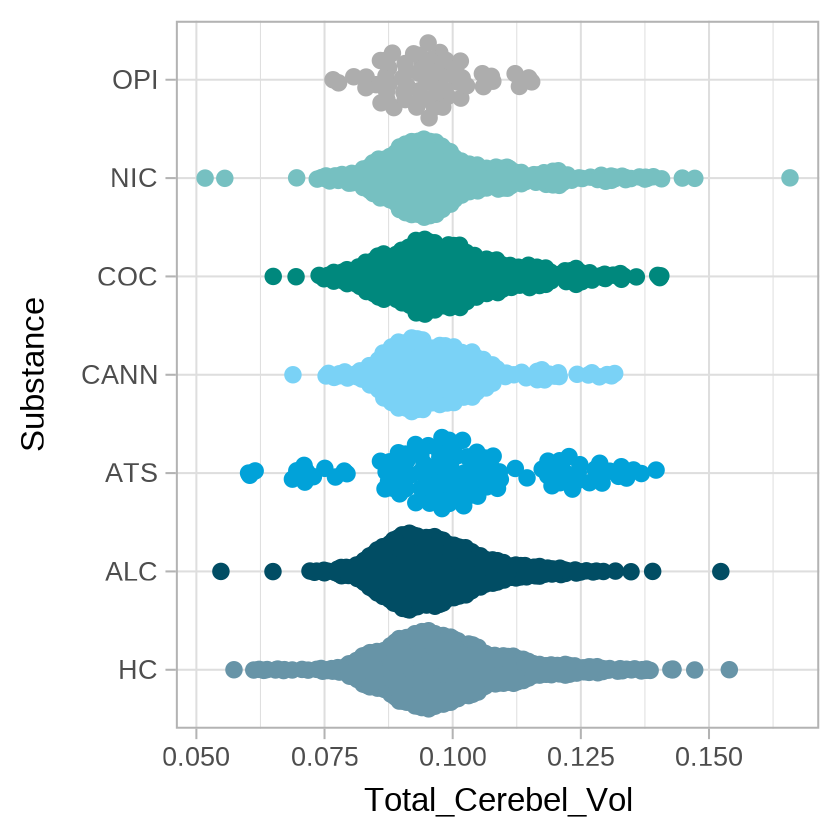

In [5]:
Acapulco_plot_total <- ggplot(Acapulco_Volumes_Cerebellum, aes(x = Substance, y = Total_Cerebel_Vol, color=Substance)) +
  geom_quasirandom() + coord_flip() + 
  scale_color_economist() +
  theme_light(base_size = 25) +
  theme(legend.position="none")

Acapulco_plot_total

#ggsave(plot = plot_total,filename = "../Figures/Substance_TotCerebellum.png",width = 42,height=38, units="cm",bg = "white")

In [6]:
Acapulco_Volumes_Cerebellum_mean <- Acapulco_Volumes_Cerebellum %>% group_by(Substance) %>% summarise_all("mean") %>% 
                          add_column(Acapulco_Volumes_Cerebellum %>% group_by(Substance) %>% summarise(n = n()) %>% select(n), .before = 2)

Acapulco_Volumes_Cerebellum_mean %>% select(c("Substance","n",length(Acapulco_Volumes_Cerebellum_mean))) %>% print()
# Acapulco_Volumes_Cerebellum_mean %>% select(c("Substance","n",length(Acapulco_Volumes_Cerebellum_mean))) %>% gt() %>%
#   gt_plt_bar_pct(column = Total_Cerebel_Vol, scaled = FALSE, fill = "lightblue") %>%
#   cols_align("center", contains("scale")) %>%
#   cols_width(3 ~ px(125)) %>% gtsave("../Figures/tab_1.png")

Warning message:
“There were 21 warnings in `summarise()`.
The first warning was:
ℹ In argument: `ID_MRI = (new("standardGeneric", .Data = function (x, ...)
  ...`.
ℹ In group 1: `Substance = HC`.
Caused by warning in `mean.default()`:
! argument is not numeric or logical: returning NA
ℹ Run `dplyr::last_dplyr_warnings()` to see the 20 remaining warnings.”


# A tibble: 7 × 3
  Substance     n Total_Cerebel_Vol
  <fct>     <int>             <dbl>
1 HC         1177            0.0985
2 ALC         914            0.0963
3 ATS         111            0.101 
4 CANN        275            0.0967
5 COC         405            0.0994
6 NIC         579            0.0981
7 OPI          58            0.0949


#### **5.2 Exploratory of assumptions**

In [7]:
ExpData(data=Acapulco_Volumes_Cerebellum,type=1) %>% print()

                                          Descriptions    Value
1                                   Sample size (nrow)     3519
2                              No. of variables (ncol)       36
3                    No. of numeric/interger variables       32
4                              No. of factor variables        3
5                                No. of text variables        1
6                             No. of logical variables        0
7                          No. of identifier variables        0
8                                No. of date variables        0
9             No. of zero variance variables (uniform)        0
10               %. of variables having complete cases 50% (18)
11   %. of variables having >0% and <50% missing cases 50% (18)
12 %. of variables having >=50% and <90% missing cases   0% (0)
13          %. of variables having >=90% missing cases   0% (0)


In [8]:
dir.create("Statistics/Assumptions/Outliers_Acapulco", recursive = TRUE, showWarnings = FALSE)

#### **5.3 Normality and homogeneity**

In [9]:
# Exploring normality by group
Acapulco_Volumes_Cerebellum %>% group_by(Substance) %>% normality() %>%
  mutate_if(is.numeric, ~round(., 4)) %>% write_csv("Statistics/Assumptions/normality_ROIs_bySUD.csv")


In [10]:
# Exploring variance homogeneity
Acapulco_Volumes_Cerebellum %>% 
    pivot_longer(cols = c(contains("."),"Total_Cerebel_Vol"),names_to = "ROI") %>% 
    group_by(Substance) %>% levene_test(value ~ ROI) %>% write_csv("Statistics/Assumptions/homogeneity_bySUD.csv")

Warning message:
“There were 7 warnings in `mutate()`.
The first warning was:
ℹ In argument: `data = map(.data$data, .f, ...)`.
Caused by warning in `leveneTest.default()`:
! group coerced to factor.
ℹ Run `dplyr::last_dplyr_warnings()` to see the 6 remaining warnings.”


#### **5.4 Outliers**

In [11]:
# Identifying outliers
Acapulco_Volumes_Cerebellum %>% select(-c("Substance","ID_MRI","Database","Age","Sex","Control")) %>% colnames() %>% 
map(~ Acapulco_Volumes_Cerebellum %>% identify_outliers(all_of(.x)) ) %>%
    set_names(Acapulco_Volumes_Cerebellum %>% select(-c("Substance","ID_MRI","Database","Age","Sex","Control")) %>% colnames() ) %>%
    iwalk(~write_csv(.x, paste0("Statistics/Assumptions/Outliers_Acapulco/",.y, ".csv")))


### **6 Hyphotesis testing**

#### **6.1 Data Preparation**

In [12]:
Acapulco_Volumes_Cerebellum_long <- Acapulco_Volumes_Cerebellum %>% 
  pivot_longer(-c(1:6),names_to = "Variables", values_to = "Values") %>%
  mutate(Variables = factor(Variables))

#### **6.2 Kruskal-Wallis analysis**

In [13]:
Acapulco_Volumes_Cerebellum.Ktest <- Acapulco_Volumes_Cerebellum_long %>% 
  group_by(Variables) %>% 
  rstatix::kruskal_test(Values~Substance) %>%
  adjust_pvalue(method = "fdr") %>% add_significance() 

Acapulco_Volumes_Cerebellum.Ktest %>% write_csv("Statistics/Acapulco_Kruskal_ROI.csv")
Acapulco_Volumes_Cerebellum.Ktest %>% filter(p.adj < 0.05) 

Variables,.y.,n,statistic,df,p,method,p.adj,p.adj.signif
<fct>,<chr>,<int>,<dbl>,<int>,<dbl>,<chr>,<dbl>,<chr>
Corpus.Medullare,Values,3519,120.53259,6,1.26e-23,Kruskal-Wallis,1.890000e-22,****
eTIV,Values,3519,219.98732,6,1.05e-44,Kruskal-Wallis,3.150000e-43,****
Left.Crus.I,Values,3519,53.59974,6,8.88e-10,Kruskal-Wallis,3.330000e-09,****
Left.Crus.II,Values,3519,19.27849,6,3.72e-03,Kruskal-Wallis,4.852174e-03,**
Left.I.III,Values,3519,47.89577,6,1.24e-08,Kruskal-Wallis,3.100000e-08,****
Left.IV,Values,3519,16.91866,6,9.59e-03,Kruskal-Wallis,1.150800e-02,*
Left.IX,Values,3519,22.25627,6,1.09e-03,Kruskal-Wallis,1.557143e-03,**
Left.V,Values,3519,73.82987,6,6.68e-14,Kruskal-Wallis,5.010000e-13,****
Left.VI,Values,3519,14.95927,6,2.06e-02,Kruskal-Wallis,2.288889e-02,*


#### **6.3 Wilcox analysis (post-hoc)**

In [14]:
Acapulco_Volumes_Cerebellum.Wtest_es <- Acapulco_Volumes_Cerebellum_long %>% 
  group_by(Variables) %>%
  wilcox_effsize(Values~Substance)

Acapulco_Volumes_Cerebellum.Wtest <- Acapulco_Volumes_Cerebellum_long %>% 
  group_by(Variables) %>% 
  rstatix::wilcox_test(Values~Substance) %>% 
  adjust_pvalue(method = "fdr") %>% add_significance() %>% 
  add_column(Acapulco_Volumes_Cerebellum.Wtest_es %>% 
               select(effsize,magnitude), .before = "p")

Acapulco_Volumes_Cerebellum.Wtest %>% write_csv("Statistics/Assumptions/Acapulco_Wilcox_ROI.csv")

#### **6.4 Visualization**

In [15]:
# Parameters:
my_pal <- rcartocolor::carto_pal(n = 10, name = "Bold")
theme_settings <- theme(text = element_text(size=23),axis.text.x = element_text(size = 20))

plot_function <- function(Volumes, met){
  y_metric <- met
  
  plot_metric <- Volumes %>%  
    select(any_of(c("Substance", y_metric))) %>% 
    ggplot(aes(x = Substance, y = .data[[y_metric]], 
               color = Substance, fill = Substance)) +
    scale_color_manual(values = my_pal, guide = "none") +
    scale_fill_manual(values = my_pal, guide = "none") +
    ggdist::stat_halfeye(
      adjust = .33, width = .7, fill = "grey85",
      interval_colour = NA, 
      position = position_nudge(x = .01),
      aes(thickness = after_stat(pdf * n))) +
    geom_boxplot(width = .1) +
    gghalves::geom_half_point(side = "l", 
                              range_scale = .3, alpha = .4, size = 1) +
    stat_summary(geom = "point",
                 fun = median, shape = 23, fill = "white",
                 color = "black", size = 2) + 
    theme_classic(base_size = 15) + theme(axis.title.x = element_blank()) +
    labs(y = "Cerebellar volume") +
    ggpubr::stat_compare_means(label = "p.signif", method = "wilcox.test",
                               ref.group = "HC", hide.ns = TRUE) + theme_settings
}

In [16]:
Acapulco_plot_regions <- colnames(Acapulco_Volumes_Cerebellum)[-c(1:7,36)] %>% 
  map(~ plot_function(Acapulco_Volumes_Cerebellum,.x)) %>% set_names(colnames(Acapulco_Volumes_Cerebellum)[-c(1:7,36)])

In [18]:
# Acapulco_plot_regions %>% iwalk(~ggsave(plot = .x, filename = paste0("Figures/Wilcox/",.y, ".png"), width = 4, height = 4, dpi = 300))

In [ ]:
Acapulco_plots_arranged <- ggarrange(Acapulco_plot_regions[[1]],Acapulco_plot_regions[[2]],
            Acapulco_plot_regions[[3]],Acapulco_plot_regions[[4]],Acapulco_plot_regions[[5]],
            Acapulco_plot_regions[[6]],Acapulco_plot_regions[[7]],Acapulco_plot_regions[[8]],Acapulco_plot_regions[[9]],Acapulco_plot_regions[[10]],
            Acapulco_plot_regions[[11]],Acapulco_plot_regions[[12]],Acapulco_plot_regions[[13]],Acapulco_plot_regions[[14]],Acapulco_plot_regions[[15]],
            Acapulco_plot_regions[[16]],Acapulco_plot_regions[[17]],Acapulco_plot_regions[[18]],Acapulco_plot_regions[[19]],Acapulco_plot_regions[[20]],
            Acapulco_plot_regions[[21]],Acapulco_plot_regions[[22]],Acapulco_plot_regions[[23]],Acapulco_plot_regions[[24]],Acapulco_plot_regions[[25]],
            Acapulco_plot_regions[[26]],Acapulco_plot_regions[[27]],Acapulco_plot_regions[[28]],
            nrow = 3,ncol = 3,labels = "AUTO")  


In [ ]:
# seq(1:length(Acapulco_plots_arranged)) %>% 
#   map(~ ggsave(units="in", width=17, height=10, dpi=300,
#                            plot = Acapulco_plots_arranged[[.x]],
#                            paste0("Figures/Wilcox/violin_",.x,".png")))    

In [ ]:
# Acapulco_Volumes_Cerebellum.Wtest$effsize %>% gghistogram()

## Analysis for MDTB

In [23]:
# Analysis by folds
MDTB_Volumes_Cerebellum <- Volumes_Cerebellum_MDTB_Harmonized %>% 
        mutate(Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC","OPI")))

### **5 Exploratory Data Analysis**

#### **5.1 Exploratory of total cerebellum volume**

In [24]:
MDTB_plot_total <- ggplot(Volumes_Cerebellum_MDTB_Harmonized, aes(x = Substance, y = Total_Cerebel_Vol, color=Substance)) +
  geom_quasirandom() + coord_flip() + 
  theme_light(base_size = 25) +
  theme(legend.position="none")

#MDTB_plot_total

#ggsave(plot = plot_total,filename = "../Figures/Substance_TotCerebellum.png",width = 42,height=38, units="cm",bg = "white")

In [25]:
MDTB_Volumes_Cerebellum_mean <- Volumes_Cerebellum_MDTB_Harmonized %>% group_by(Substance) %>% summarise_all("mean") %>% 
                          add_column(Volumes_Cerebellum_MDTB_Harmonized %>% group_by(Substance) %>% summarise(n = n()) %>% select(n), .before = 2)

# MDTB_Volumes_Cerebellum_mean %>% select(c("Substance","n",length(MDTB_Volumes_Cerebellum_mean))) %>% gt() %>%
#   gt_plt_bar_pct(column = Total_Cerebel_Vol, scaled = FALSE, fill = "lightblue") %>%
#   cols_align("center", contains("scale")) %>%
#   cols_width(3 ~ px(125)) %>% gtsave("../Figures/tab_1.png")

Warning message:
“There were 21 warnings in `summarise()`.
The first warning was:
ℹ In argument: `ID_MRI = (new("standardGeneric", .Data = function (x, ...)
  ...`.
ℹ In group 1: `Substance = "ALC"`.
Caused by warning in `mean.default()`:
! argument is not numeric or logical: returning NA
ℹ Run `dplyr::last_dplyr_warnings()` to see the 20 remaining warnings.”


#### **5.2 Exploratory of assumptions**

In [26]:
ExpData(data=MDTB_Volumes_Cerebellum,type=1)

Descriptions,Value
<chr>,<chr>
Sample size (nrow),3519
No. of variables (ncol),19
No. of numeric/interger variables,15
No. of factor variables,3
No. of text variables,1
No. of logical variables,0
No. of identifier variables,0
No. of date variables,0
No. of zero variance variables (uniform),0


#### **5.3 Normality and homogeneity**

In [31]:
dir.create("Statistics/Assumptions/Outliers_MDTB/", recursive = TRUE)

Warning message in dir.create("Statistics/Assumptions/Outliers_MDTB/", recursive = TRUE):
“'Statistics/Assumptions/Outliers_MDTB' already exists”


In [32]:
# Exploring normality 
MDTB_Volumes_Cerebellum %>% normality() %>%
  mutate_if(is.numeric, ~round(., 4)) %>% write_csv("Statistics/Assumptions/MDTB_normality_ROIs.csv")

# Exploring normality by group
MDTB_Volumes_Cerebellum %>% group_by(Substance) %>% normality() %>%
  mutate_if(is.numeric, ~round(., 4)) %>% write_csv("Statistics/Assumptions/MDTB_normality_ROIs_bySUD.csv")


#### **5.4 Outliers**

In [33]:
# Identifying outliers
MDTB_Volumes_Cerebellum %>% select(-c("Substance","ID_MRI","Age","Sex","Database","Control")) %>% colnames() %>% 
map(~ MDTB_Volumes_Cerebellum %>% identify_outliers(all_of(.x)) ) %>%
    set_names(MDTB_Volumes_Cerebellum %>% select(-c("Substance","ID_MRI","Age","Sex","Database","Control")) %>% colnames() ) %>%
    iwalk(~write_csv(.x, paste0("Statistics/Assumptions/Outliers_MDTB/",.y, ".csv")))


### **6 Hyphotesis testing**

#### **6.1 Data Preparation**

In [34]:
MDTB_Volumes_Cerebellum_long <- MDTB_Volumes_Cerebellum %>% 
  pivot_longer(-c(1:7),names_to = "Variables", values_to = "Values")

#### **6.2 Kruskal-Wallis analysis**

In [35]:
MDTB_Volumes_Cerebellum.Ktest <- MDTB_Volumes_Cerebellum_long %>% 
  group_by(Variables) %>% 
  rstatix::kruskal_test(Values~Substance) %>%
  adjust_pvalue(method = "fdr") %>% add_significance() 

MDTB_Volumes_Cerebellum.Ktest %>% write_csv("Statistics/MDTB_Kruskal_ROI.csv")
MDTB_Volumes_Cerebellum.Ktest %>% filter(p.adj < 0.05) 

Variables,.y.,n,statistic,df,p,method,p.adj,p.adj.signif
<chr>,<chr>,<int>,<dbl>,<int>,<dbl>,<chr>,<dbl>,<chr>
Left.Crus.I,Values,3519,53.59974,6,8.88e-10,Kruskal-Wallis,1.065600e-09,****
eTIV,Values,3519,219.98732,6,1.05e-44,Kruskal-Wallis,1.260000e-43,****
region_1,Values,3519,64.97188,6,4.37e-12,Kruskal-Wallis,1.311000e-11,****
region_10,Values,3519,59.91215,6,4.69e-11,Kruskal-Wallis,9.380000e-11,****
region_2,Values,3519,52.67855,6,1.36e-09,Kruskal-Wallis,1.483636e-09,****
region_3,Values,3519,79.00490,6,5.73e-15,Kruskal-Wallis,3.438000e-14,****
region_4,Values,3519,39.60196,6,5.45e-07,Kruskal-Wallis,5.450000e-07,****
region_5,Values,3519,65.31656,6,3.72e-12,Kruskal-Wallis,1.311000e-11,****
region_6,Values,3519,56.10386,6,2.77e-10,Kruskal-Wallis,3.693333e-10,****


#### **6.2 Wilcox analysis (post-hoc)**

In [36]:
MDTB_Volumes_Cerebellum.Wtest_es <- MDTB_Volumes_Cerebellum_long %>% 
  group_by(Variables) %>%
  wilcox_effsize(Values~Substance)

MDTB_Volumes_Cerebellum.Wtest <- MDTB_Volumes_Cerebellum_long %>% 
  group_by(Variables) %>% 
  rstatix::wilcox_test(Values~Substance) %>% 
  adjust_pvalue(method = "fdr") %>% add_significance() %>% 
  add_column(MDTB_Volumes_Cerebellum.Wtest_es %>% 
               select(effsize,magnitude), .before = "p")

MDTB_Volumes_Cerebellum.Wtest %>% write_csv("Statistics/Assumptions/MDTB_Wilcox_ROI.csv")

#### **6.3 Visualization**

In [37]:
MDTB_plot_regions <- colnames(MDTB_Volumes_Cerebellum)[-c(1:7,36)] %>% 
  map(~ plot_function(MDTB_Volumes_Cerebellum,.x)) %>% set_names(colnames(MDTB_Volumes_Cerebellum)[-c(1:7,36)])

In [39]:
# MDTB_plot_regions %>% iwalk(~ggsave(plot = .x, filename = paste0("Figures/Wilcox_MDTB/",.y, ".png"), width = 4, height = 4, dpi = 300))

In [ ]:
MDTB_plots_arranged <- ggarrange(MDTB_plot_regions[[1]],MDTB_plot_regions[[2]],
            MDTB_plot_regions[[3]],MDTB_plot_regions[[4]],MDTB_plot_regions[[5]],
            MDTB_plot_regions[[6]],MDTB_plot_regions[[7]],MDTB_plot_regions[[8]],MDTB_plot_regions[[9]],MDTB_plot_regions[[10]],
            nrow = 4,ncol = 3,labels = "AUTO")  
